# Netflix Customer Churn — Business & Data Understanding (CRISP-DM)

**Mata kuliah:** Data Science — UPN "Veteran" Yogyakarta, Informatika (UTS Ganjil 2026/2027)
**Judul laporan:** Analisis Pola Churn Pelanggan Netflix Berdasarkan Perilaku Menonton dan Karakteristik Langganan Menggunakan Data Mining

Notebook ini mereproduksi seluruh angka, tabel, dan gambar pada bagian **C. Data Understanding** laporan beserta Lampiran A dan B.

**Cara pakai:** letakkan notebook ini sejajar dengan folder `data/`, lalu jalankan semua sel berurutan (*Kernel → Restart & Run All*). Hasil gambar disimpan ke `figures/` dan tabel ke `outputs/`.

> Catatan: dataset ini diindikasikan sintetis (lihat bagian 9). Seluruh temuan berlaku untuk dataset ini saja dan bersifat asosiasi, bukan sebab-akibat.

## 0. Konfigurasi dan impor

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DATA_PATH = Path("data/netflix_customer_churn.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
RED, TEAL, ORANGE, BLUE = "#E63946", "#2A9D8F", "#F4A261", "#457B9D"
ALPHA = 0.05

def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()

## 1. Memuat data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
print("Ukuran berkas (byte):", DATA_PATH.stat().st_size)
df.head()

Ukuran data: (5000, 14)
Ukuran berkas (byte): 545934


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [3]:
df.dtypes.to_frame("tipe").join(df.nunique().rename("nilai_unik"))

,tipe,nilai_unik
customer_id,str,5000
age,int64,53
gender,str,3
subscription_type,str,3
watch_hours,float64,2343
last_login_days,int64,61
region,str,6
device,str,5
monthly_fee,float64,3
churned,int64,2


## 2. Data dictionary dan verifikasi asumsi (Bagian B.5 & C.2)

In [4]:
num_cols = ["age", "watch_hours", "last_login_days", "monthly_fee", "number_of_profiles", "avg_watch_time_per_day"]
cat_cols = ["gender", "subscription_type", "region", "device", "payment_method", "favorite_genre"]

print("customer_id unik:", df["customer_id"].nunique(), "dari", len(df))
for c in cat_cols:
    print(f"{c:18s}", sorted(df[c].unique()))
print("monthly_fee x subscription_type:")
print(pd.crosstab(df["subscription_type"], df["monthly_fee"]))

customer_id unik: 5000 dari 5000
gender             ['Female', 'Male', 'Other']
subscription_type  ['Basic', 'Premium', 'Standard']
region             ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']
device             ['Desktop', 'Laptop', 'Mobile', 'TV', 'Tablet']
payment_method     ['Credit Card', 'Crypto', 'Debit Card', 'Gift Card', 'PayPal']
favorite_genre     ['Action', 'Comedy', 'Documentary', 'Drama', 'Horror', 'Romance', 'Sci-Fi']
monthly_fee x subscription_type:
monthly_fee        8.99   13.99  17.99
subscription_type                     
Basic               1661      0      0
Premium                0      0   1693
Standard               0   1646      0


## 3. Kualitas data (Tabel 8)

### 3a. Missing value dan duplikasi

In [5]:
print("Total missing value:", int(df.isna().sum().sum()))
print("Baris duplikat:", int(df.duplicated().sum()))
print("customer_id duplikat:", int(df["customer_id"].duplicated().sum()))

Total missing value: 0
Baris duplikat: 0
customer_id duplikat: 0


### 3b. Outlier (aturan IQR 1,5×) — Tabel A2

In [6]:
rows = []
for c in ["age", "watch_hours", "last_login_days", "avg_watch_time_per_day", "number_of_profiles"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"kolom": c, "batas_bawah": round(lo, 2), "batas_atas": round(hi, 2),
                 "jumlah_outlier": n, "persen": round(100 * n / len(df), 1),
                 "skewness": round(df[c].skew(), 2)})
outlier_df = pd.DataFrame(rows)
outlier_df.to_csv(OUT_DIR / "outlier_iqr.csv", index=False)
outlier_df

,kolom,batas_bawah,batas_atas,jumlah_outlier,persen,skewness
0,age,-12.00,100.00,0,0.0,0.01
1,watch_hours,-15.70,35.07,238,4.8,2.26
2,last_login_days,-30.00,90.00,0,0.0,-0.03
3,avg_watch_time_per_day,-0.81,1.64,549,11.0,15.83
4,number_of_profiles,-1.00,7.00,0,0.0,-0.02


### 3c. Inkonsistensi kolom `avg_watch_time_per_day`

In [7]:
derived = (df["watch_hours"] / (df["last_login_days"] + 1)).round(2)
diff = (df["avg_watch_time_per_day"] - derived).abs()
print("Selisih maksimum terhadap round(watch_hours/(last_login_days+1), 2):", round(diff.max(), 4))
print("Baris dengan selisih > 0,011:", int((diff > 0.011).sum()))
print("Baris avg_watch_time_per_day > 24 jam/hari:", int((df["avg_watch_time_per_day"] > 24).sum()),
      "| maksimum:", df["avg_watch_time_per_day"].max())
print("Nilai ekstrem sah -> avg_watch_time_per_day == 0:", int((df["avg_watch_time_per_day"] == 0).sum()),
      "| last_login_days == 0:", int((df["last_login_days"] == 0).sum()),
      "| watch_hours < 0,1:", int((df["watch_hours"] < 0.1).sum()))

Selisih maksimum terhadap round(watch_hours/(last_login_days+1), 2): 0.01
Baris dengan selisih > 0,011: 0
Baris avg_watch_time_per_day > 24 jam/hari: 10 | maksimum: 98.42
Nilai ekstrem sah -> avg_watch_time_per_day == 0: 52 | last_login_days == 0: 81 | watch_hours < 0,1: 27


## 4. Statistik deskriptif (Tabel A1)

In [8]:
desc = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max", "mean"]]
desc.columns = ["Min", "Q1", "Median", "Q3", "Maks", "Rerata"]
desc.round(2)

,Min,Q1,Median,Q3,Maks,Rerata
age,18.00,30.00,44.00,58.00,70.00,43.85
watch_hours,0.01,3.34,8.00,16.03,110.40,11.65
last_login_days,0.00,15.00,30.00,45.00,60.00,30.09
monthly_fee,8.99,8.99,13.99,17.99,17.99,13.68
number_of_profiles,1.00,2.00,3.00,4.00,5.00,3.02
avg_watch_time_per_day,0.00,0.11,0.29,0.72,98.42,0.87


## 5. Distribusi target dan paket (Gambar 1)

Churn: 2515 (50.3%) | Aktif: 2485 (49.7%)
subscription_type
Basic       61.8
Standard    45.4
Premium     43.7
Name: churned, dtype: float64


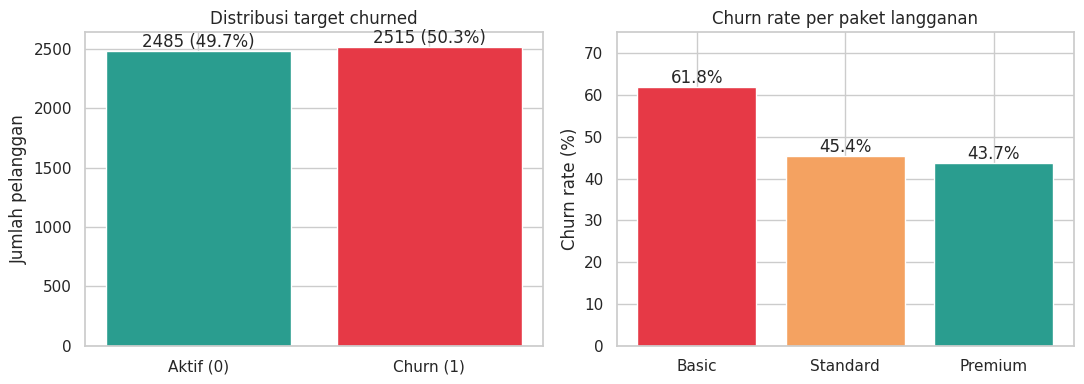

In [9]:
n_churn = int(df["churned"].sum()); n_active = len(df) - n_churn
print(f"Churn: {n_churn} ({100*n_churn/len(df):.1f}%) | Aktif: {n_active} ({100*n_active/len(df):.1f}%)")

order_sub = ["Basic", "Standard", "Premium"]
rate_sub = df.groupby("subscription_type")["churned"].mean().reindex(order_sub) * 100
print(rate_sub.round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
vals = [n_active, n_churn]
ax[0].bar(["Aktif (0)", "Churn (1)"], vals, color=[TEAL, RED])
for i, v in enumerate(vals):
    ax[0].text(i, v, f"{v} ({100*v/len(df):.1f}%)", ha="center", va="bottom")
ax[0].set_ylabel("Jumlah pelanggan"); ax[0].set_title("Distribusi target churned")
ax[1].bar(order_sub, rate_sub.values, color=[RED, ORANGE, TEAL])
for i, v in enumerate(rate_sub.values):
    ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
ax[1].set_ylabel("Churn rate (%)"); ax[1].set_title("Churn rate per paket langganan"); ax[1].set_ylim(0, 75)
plt.tight_layout(); savefig("fig1_target_dan_paket.png")

## 6. Perilaku menonton: recency dan intensitas (Gambar 2)

In [10]:
for c in ["watch_hours", "last_login_days"]:
    g = df.groupby("churned")[c].median()
    u, p = stats.mannwhitneyu(df.loc[df.churned == 1, c], df.loc[df.churned == 0, c], alternative="two-sided")
    print(f"{c}: median churn={g[1]:.2f} | median aktif={g[0]:.2f} | Mann-Whitney p={p:.3g}")

print()
print("Spearman terhadap churned:")
print(df[num_cols + ["churned"]].corr(method="spearman")["churned"].drop("churned").round(3))

watch_hours: median churn=4.06 | median aktif=13.86 | Mann-Whitney p=0
last_login_days: median churn=41.00 | median aktif=19.00 | Mann-Whitney p=1.88e-243

Spearman terhadap churned:
age                      -0.004
watch_hours              -0.541
last_login_days           0.471
monthly_fee              -0.148
number_of_profiles       -0.159
avg_watch_time_per_day   -0.734
Name: churned, dtype: float64


login_bin
0-7      13.4
8-14     27.0
15-30    32.0
31-45    74.7
46-60    75.5

watch_q
Q1 (terendah)     85.7
Q2                73.1
Q3                44.0
Q4                40.5
Q5 (tertinggi)     8.1


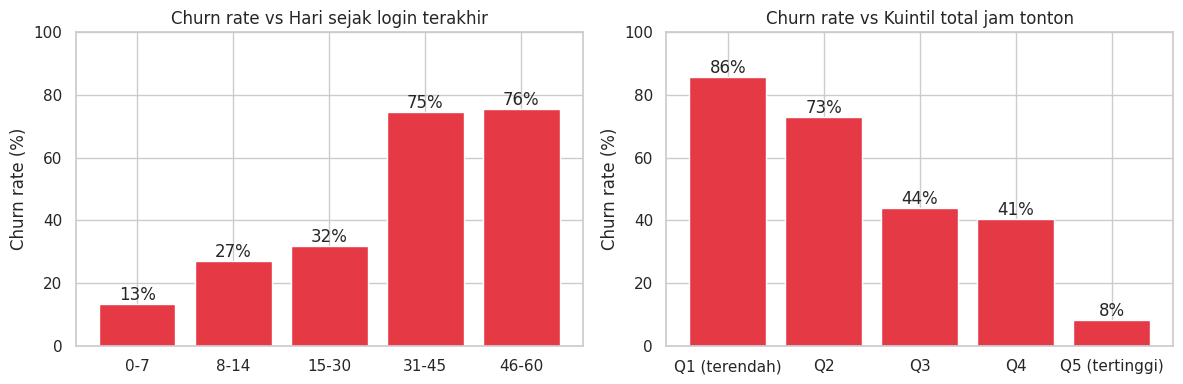

In [11]:
bins = [-1, 7, 14, 30, 45, 60]
labels = ["0-7", "8-14", "15-30", "31-45", "46-60"]
df["login_bin"] = pd.cut(df["last_login_days"], bins=bins, labels=labels)
rate_login = df.groupby("login_bin", observed=True)["churned"].mean() * 100

df["watch_q"] = pd.qcut(df["watch_hours"], 5, labels=["Q1 (terendah)", "Q2", "Q3", "Q4", "Q5 (tertinggi)"])
rate_watch = df.groupby("watch_q", observed=True)["churned"].mean() * 100
print(rate_login.round(1).to_string()); print(); print(rate_watch.round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(labels, rate_login.values, color=RED)
for i, v in enumerate(rate_login.values): ax[0].text(i, v, f"{v:.0f}%", ha="center", va="bottom")
ax[0].set_title("Churn rate vs Hari sejak login terakhir"); ax[0].set_ylabel("Churn rate (%)"); ax[0].set_ylim(0, 100)
ax[1].bar(rate_watch.index.astype(str), rate_watch.values, color=RED)
for i, v in enumerate(rate_watch.values): ax[1].text(i, v, f"{v:.0f}%", ha="center", va="bottom")
ax[1].set_title("Churn rate vs Kuintil total jam tonton"); ax[1].set_ylabel("Churn rate (%)"); ax[1].set_ylim(0, 100)
plt.tight_layout(); savefig("fig2_recency_dan_intensitas.png")

> **Peringatan interpretasi:** `last_login_days` dapat merupakan *akibat* churn, bukan sebab. Pola di atas adalah asosiasi dan menimbulkan risiko *temporal leakage* bila dipakai sebagai fitur prediksi (dibahas lagi pada tahap Modeling).

## 7. Variabel kategorikal (Tabel 9, Gambar 3)

In [12]:
def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

chi_rows = []
for c in ["subscription_type", "payment_method", "number_of_profiles",
          "favorite_genre", "gender", "region", "device"]:
    ct = pd.crosstab(df[c], df["churned"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rates = df.groupby(c)["churned"].mean() * 100
    chi_rows.append({"variabel": c, "churn_min_%": round(rates.min(), 1), "churn_maks_%": round(rates.max(), 1),
                     "chi2": round(chi2, 1), "dof": dof, "p_value": p,
                     "cramers_v": round(cramers_v(ct), 3), "signifikan_5%": p < ALPHA})
chi_df = pd.DataFrame(chi_rows)
chi_df.to_csv(OUT_DIR / "chi_square.csv", index=False)
chi_df

,variabel,churn_min_%,churn_maks_%,chi2,dof,p_value,cramers_v,signifikan_5%
0,subscription_type,43.7,61.8,133.3,2,1.145735e-29,0.163,True
1,payment_method,43.6,59.7,96.9,4,4.478433e-20,0.139,True
2,number_of_profiles,37.5,58.6,174.0,4,1.457986e-36,0.187,True
3,favorite_genre,47.1,52.4,7.0,6,3.235910e-01,0.037,False
4,gender,49.8,51.1,0.7,2,7.224877e-01,0.011,False
5,region,48.3,51.7,2.7,5,7.531078e-01,0.023,False
6,device,49.2,51.8,1.4,4,8.361579e-01,0.017,False


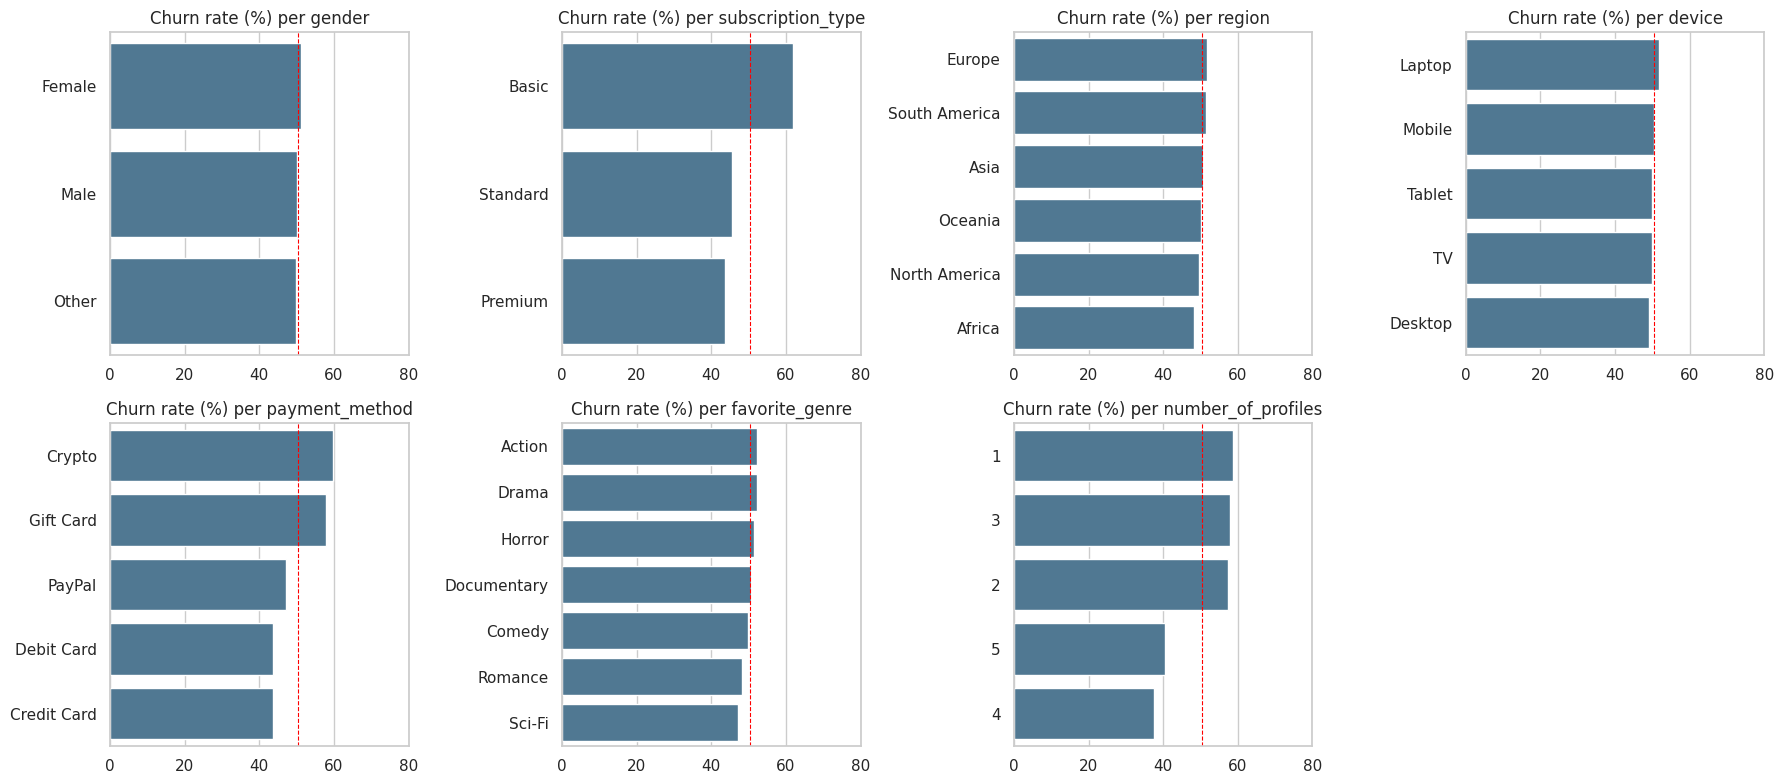

In [13]:
cat_plot = ["gender", "subscription_type", "region", "device", "payment_method", "favorite_genre", "number_of_profiles"]
overall = df["churned"].mean() * 100
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, cat_plot):
    r = (df.groupby(c)["churned"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=r.values, y=r.index.astype(str), color=BLUE, ax=ax, orient="h")
    ax.axvline(overall, color="red", ls="--", lw=0.8)
    ax.set_xlim(0, 80); ax.set_title(f"Churn rate (%) per {c}"); ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.tight_layout(); savefig("fig3_churn_per_kategori.png")

Detail yang disebut pada laporan: metode pembayaran, jumlah profil, dan usia.

In [14]:
print((df.groupby("payment_method")["churned"].mean() * 100).sort_values(ascending=False).round(1).to_string())
print()
print((df.groupby("number_of_profiles")["churned"].mean() * 100).round(1).to_string())
print()
print("Paket x metode pembayaran (churn %):")
print((df.pivot_table(index="subscription_type", columns="payment_method", values="churned", aggfunc="mean") * 100).round(1).reindex(order_sub))
print()
u, p = stats.mannwhitneyu(df.loc[df.churned == 1, "age"], df.loc[df.churned == 0, "age"])
print(f"Usia: median churn={df.loc[df.churned==1,'age'].median()} | aktif={df.loc[df.churned==0,'age'].median()} | p={p:.3f}")

payment_method
Crypto         59.7
Gift Card      57.8
PayPal         47.1
Debit Card     43.7
Credit Card    43.6

number_of_profiles
1    58.6
2    57.4
3    57.8
4    37.5
5    40.6

Paket x metode pembayaran (churn %):
payment_method     Credit Card  Crypto  Debit Card  Gift Card  PayPal
subscription_type                                                    
Basic                     59.4    62.7        60.1       64.7    62.6
Standard                  36.2    59.2        36.5       56.7    38.5
Premium                   33.6    57.7        34.9       52.4    38.8

Usia: median churn=44.0 | aktif=44.0 | p=0.780


## 8. Uji Mann-Whitney variabel numerik (Tabel A3)

In [15]:
mw_rows = []
for c in ["age", "watch_hours", "last_login_days", "avg_watch_time_per_day", "monthly_fee"]:
    a, b = df.loc[df.churned == 1, c], df.loc[df.churned == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    mw_rows.append({"variabel": c, "median_churn": round(a.median(), 2), "median_aktif": round(b.median(), 2),
                    "U": u, "p_value": p, "signifikan_5%": p < ALPHA})
mw_df = pd.DataFrame(mw_rows)
mw_df.to_csv(OUT_DIR / "mann_whitney.csv", index=False)
mw_df

,variabel,median_churn,median_aktif,U,p_value,signifikan_5%
0,age,44.00,44.00,3110654.0,7.802933e-01,False
1,watch_hours,4.06,13.86,1171589.5,0.000000e+00,True
2,last_login_days,41.00,19.00,4825226.5,1.878447e-243,True
3,avg_watch_time_per_day,0.12,0.72,477221.5,0.000000e+00,True
4,monthly_fee,13.99,13.99,2621933.0,1.417874e-25,True


## 9. Representativitas (Bagian C.5)

In [16]:
print("Distribusi proporsi (%):")
for c in ["gender", "region", "device", "payment_method"]:
    print(f"\n{c}"); print((df[c].value_counts(normalize=True) * 100).round(1).to_string())
print("\nSkewness age:", round(df["age"].skew(), 3), "| rentang:", df["age"].min(), "-", df["age"].max())
print("Churn rate keseluruhan:", round(overall, 1), "%")

Distribusi proporsi (%):

gender
gender
Female    34.2
Male      33.1
Other     32.7

region
region
South America    17.5
Europe           17.3
North America    17.0
Asia             16.8
Africa           16.1
Oceania          15.3

device
device
Tablet     21.0
Laptop     20.1
Mobile     20.1
TV         19.9
Desktop    19.0

payment_method
payment_method
Debit Card     20.6
PayPal         20.5
Crypto         19.9
Gift Card      19.5
Credit Card    19.5

Skewness age: 0.006 | rentang: 18 - 70
Churn rate keseluruhan: 50.3 %


## 10. Nilai bisnis (Bagian B.1 dan B.7)

In [17]:
total_fee = df["monthly_fee"].sum()
churn_fee = df.loc[df.churned == 1, "monthly_fee"].sum()
print(f"Total biaya bulanan: USD {total_fee:,.2f}")
print(f"Akun churn: USD {churn_fee:,.2f} ({100*churn_fee/total_fee:.1f}%)")
print((df[df.churned == 1].groupby("subscription_type")["monthly_fee"].sum().reindex(order_sub)).round(2).to_string())

active = df[df.churned == 0]
risk = active[active["last_login_days"] > 30]
print(f"\nPelanggan aktif: {len(active)} | tidak login > 30 hari: {len(risk)} ({100*len(risk)/len(active):.1f}%)")
print(f"Revenue-at-risk bulanan pelanggan aktif tersebut: USD {risk['monthly_fee'].sum():,.2f}")

Total biaya bulanan: USD 68,417.00
Akun churn: USD 33,009.85 (48.2%)
subscription_type
Basic        9232.73
Standard    10464.52
Premium     13312.60

Pelanggan aktif: 2485 | tidak login > 30 hari: 615 (24.7%)
Revenue-at-risk bulanan pelanggan aktif tersebut: USD 9,088.85


## 11. Gambar lampiran (B1–B4)

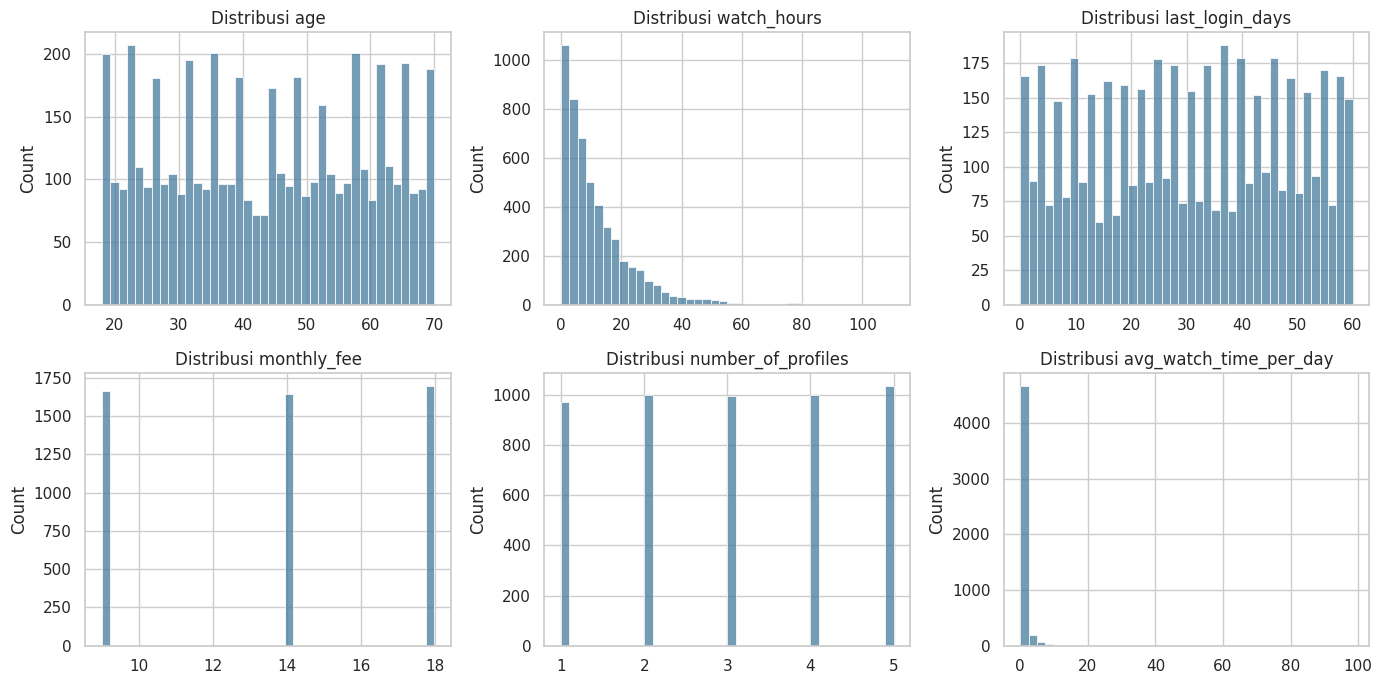

In [18]:
# B1. Distribusi variabel numerik
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c], bins=40, color=BLUE, ax=ax)
    ax.set_title(f"Distribusi {c}"); ax.set_xlabel("")
plt.tight_layout(); savefig("figB1_distribusi_numerik.png")

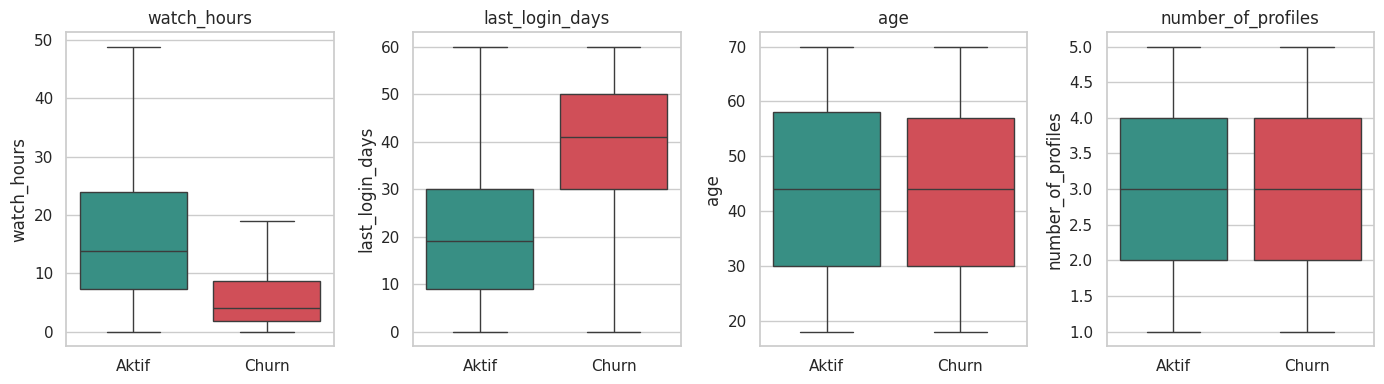

In [19]:
# B2. Boxplot menurut status churn (outlier ekstrem disembunyikan)
box_cols = ["watch_hours", "last_login_days", "age", "number_of_profiles"]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axes, box_cols):
    sns.boxplot(data=df, x="churned", y=c, showfliers=False, palette=[TEAL, RED], ax=ax)
    ax.set_xticklabels(["Aktif", "Churn"]); ax.set_xlabel(""); ax.set_title(c)
plt.tight_layout(); savefig("figB2_boxplot_menurut_churn.png")

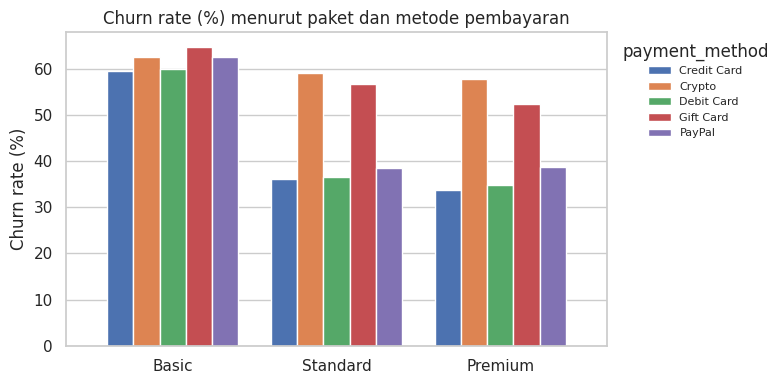

In [20]:
# B3. Churn rate menurut paket dan metode pembayaran
piv = (df.pivot_table(index="subscription_type", columns="payment_method", values="churned", aggfunc="mean") * 100).reindex(order_sub)
ax = piv.plot(kind="bar", figsize=(8, 4), width=0.8, rot=0)
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(""); ax.set_title("Churn rate (%) menurut paket dan metode pembayaran")
ax.grid(axis="x", visible=False)
ax.legend(title="payment_method", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.tight_layout(); savefig("figB3_paket_x_pembayaran.png")

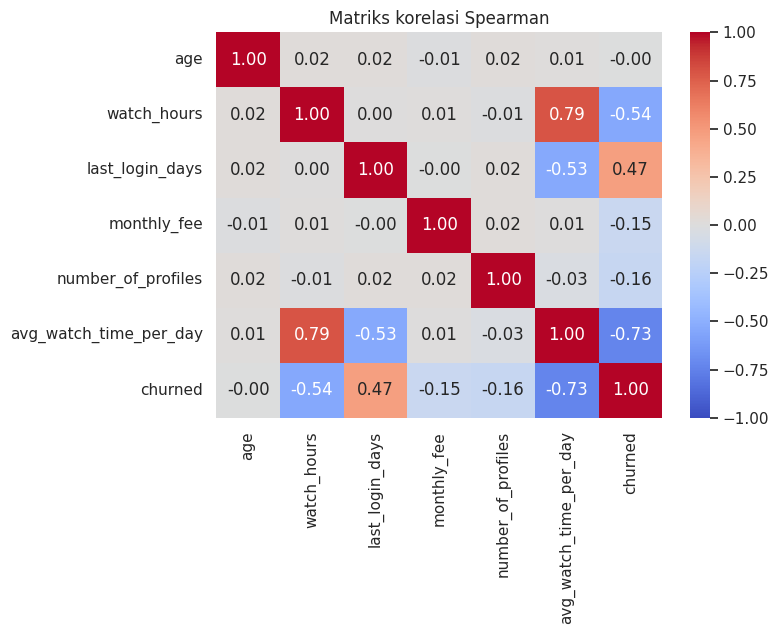

In [21]:
# B4. Matriks korelasi Spearman
corr = df[num_cols + ["churned"]].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriks korelasi Spearman")
plt.tight_layout(); savefig("figB4_korelasi_spearman.png")

## 12. Implikasi untuk Data Preparation (Bagian C.6)

- Buang `customer_id` dari fitur.
- Pilih salah satu antara `subscription_type` dan `monthly_fee` (berpadanan 1:1).
- Putuskan perlakuan `avg_watch_time_per_day` (turunan dari `watch_hours` dan `last_login_days`) dan evaluasi `last_login_days` terhadap risiko *temporal leakage*.
- Transformasi log / skala robust untuk `watch_hours`; *one-hot encoding* untuk kategorikal; *stratified split* 80:20.
- Bandingkan model penuh dengan model ringkas tanpa variabel yang tidak berasosiasi (`gender`, `region`, `device`, `favorite_genre`, `age`).